# Part 1 — Explore the data and why a simple model fails
Follows the Coding Club tutorial **[Introduction to linear mixed models](https://ourcodingclub.github.io/tutorials/mixed-models/)**,
sections *Explore the data*, *Fit all data in one analysis*, *Run multiple analyses* and *Modify the current model*.

Each step shows the tutorial's R code first, then the Python equivalent. Read the explanation on the web page, run the cell here.

**Packages:** `pandas`, `numpy`, `matplotlib`, `statsmodels`, `scipy`
(`pip install pandas numpy matplotlib statsmodels scipy`).

| R | Python |
|---|---|
| `lm(y ~ x, data)` | `smf.ols("y ~ x", data).fit()` |
| `summary(m)` | `m.summary()` |
| `ggplot(...)` | `matplotlib` |

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings("ignore")          # statsmodels convergence chatter; check m.converged instead
pd.set_option("display.width", 140)

# dragons.csv sits next to this notebook (converted from the tutorial's dragons.RData).
# To read the original RData instead:  import pyreadr; dragons = pyreadr.read_r("dragons.RData")["dragons"]
dragons = pd.read_csv("dragons.csv")
dragons["bodyLength2"] = (dragons["bodyLength"] - dragons["bodyLength"].mean()) / dragons["bodyLength"].std()

## Explore the data

**Tutorial R block 1**
```r
load("dragons.RData")
head(dragons)
```
Python equivalent:

In [7]:
dragons.head()

,testScore,bodyLength,mountainRange,X,site,bodyLength2
0,16.147309,165.548520,Bavarian,NaN,a,-2.206233
1,33.886183,167.559314,Bavarian,NaN,a,-2.082204
2,6.038333,165.882952,Bavarian,NaN,a,-2.185605
3,18.838821,167.685525,Bavarian,NaN,a,-2.074419
4,33.862328,169.959681,Bavarian,NaN,a,-1.934145


In [13]:
dragons.shape

(480, 6)

The extra column `X` is empty in the original file and can be ignored.

**Tutorial R block 2**
```r
hist(dragons$testScore)  # seems close to a normal distribution - good!
```
Python equivalent:

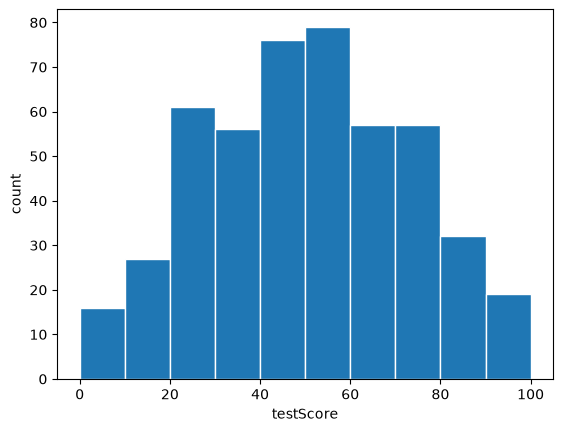

In [8]:
plt.hist(dragons["testScore"], bins=10, edgecolor="white")
plt.xlabel("testScore"); plt.ylabel("count"); plt.show()

**Tutorial R block 3** — already done in the setup cell
```r
dragons$bodyLength2 <- scale(dragons$bodyLength, center = TRUE, scale = TRUE)
```
Python equivalent:

In [9]:
# scale() = subtract the mean, divide by the SD
dragons[["bodyLength", "bodyLength2"]].describe().round(2)

,bodyLength,bodyLength2
count,480.00,480.00
mean,201.32,0.00
std,16.21,1.00
min,162.33,-2.40
25%,191.76,-0.59
50%,202.91,0.10
75%,213.14,0.73
max,236.36,2.16


## Fit all data in one analysis

**Tutorial R block 4**
```r
basic.lm <- lm(testScore ~ bodyLength2, data = dragons)
summary(basic.lm)
```
Python equivalent:

In [10]:
basic_lm = smf.ols("testScore ~ bodyLength2", data=dragons).fit()
print(basic_lm.summary())

                            OLS Regression Results                            
Dep. Variable:              testScore   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.151
Method:                 Least Squares   F-statistic:                     86.25
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           5.59e-19
Time:                        18:46:46   Log-Likelihood:                -2146.0
No. Observations:                 480   AIC:                             4296.
Df Residuals:                     478   BIC:                             4304.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      50.3860      0.968     52.072      

Bigger dragons seem to score higher. The tutorial explains why this is suspicious.

**Tutorial R block 5**
```r
(prelim_plot <- ggplot(dragons, aes(x = bodyLength, y = testScore)) +
  geom_point() +
  geom_smooth(method = "lm"))
```
Python equivalent:

In [12]:
fit = smf.ols("testScore ~ bodyLength", data=dragons).fit()
xs = pd.DataFrame({"bodyLength": np.linspace(dragons.bodyLength.min(), dragons.bodyLength.max(), 100)})
pr = fit.get_prediction(xs).summary_frame()
pr

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,28.751867,2.522499,23.795309,33.708425,-13.197868,70.701602
1,29.166817,2.481296,24.291221,34.042412,-12.773429,71.107063
2,29.581766,2.440214,24.786894,34.376639,-12.349172,71.512705
3,29.996716,2.399262,25.282313,34.711119,-11.925097,71.918529
4,30.411666,2.358444,25.777466,35.045866,-11.501203,72.324535
...,...,...,...,...,...,...
95,68.172097,2.145736,63.955857,72.388338,26.303380,110.040815
96,68.587047,2.185709,64.292262,72.881832,26.710347,110.463747
97,69.001997,2.225861,64.628316,73.375678,27.117132,110.886862
98,69.416947,2.266182,64.964036,73.869857,27.523735,111.310159


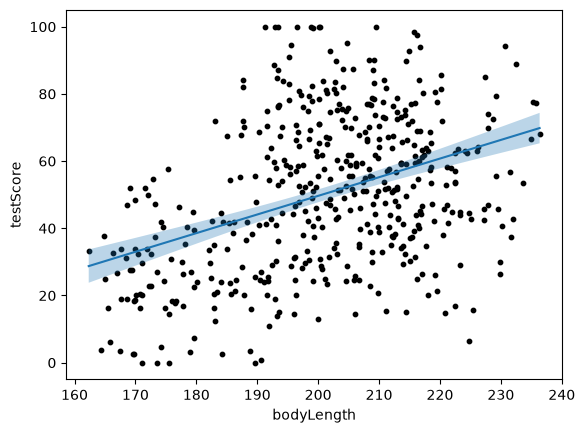

In [15]:
fit = smf.ols("testScore ~ bodyLength", data=dragons).fit()
xs = pd.DataFrame({"bodyLength": np.linspace(dragons.bodyLength.min(), dragons.bodyLength.max(), 100)})
pr = fit.get_prediction(xs).summary_frame()
plt.scatter(dragons.bodyLength, dragons.testScore, s=10, color="k")
plt.plot(xs.bodyLength, pr["mean"], color="tab:blue")
plt.fill_between(xs.bodyLength, pr["mean_ci_lower"], pr["mean_ci_upper"], alpha=0.3)
plt.xlabel("bodyLength"); plt.ylabel("testScore"); plt.show()

**Tutorial R block 6** — residuals vs fitted
```r
plot(basic.lm, which = 1)  # not perfect...
```
Python equivalent:

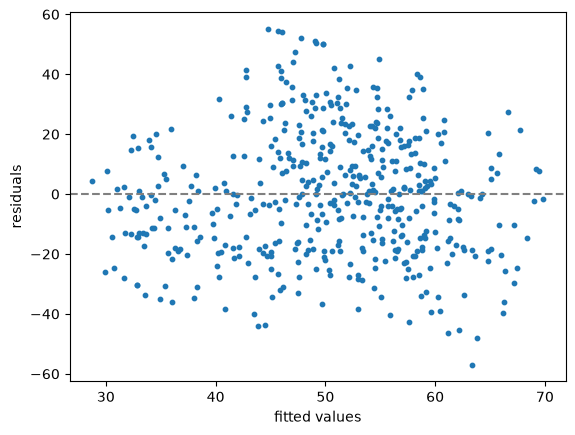

In [16]:
plt.scatter(basic_lm.fittedvalues, basic_lm.resid, s=10)
plt.axhline(0, ls="--", color="grey")
plt.xlabel("fitted values"); plt.ylabel("residuals"); plt.show()

**Tutorial R block 7** — QQ plot
```r
plot(basic.lm, which = 2)  # a bit off at the extremes
```
Python equivalent:

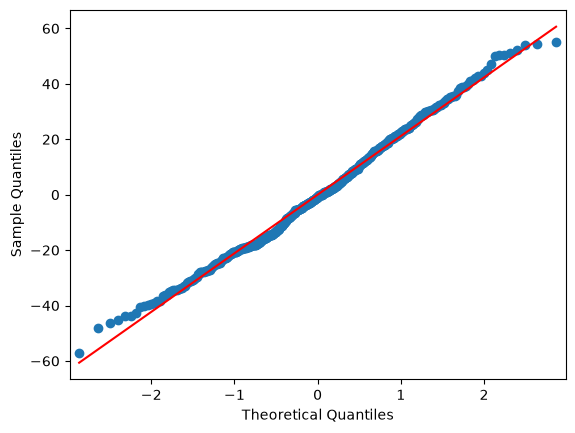

In [17]:
sm.qqplot(basic_lm.resid, line="s"); plt.show()

**Tutorial R block 8**
```r
boxplot(testScore ~ mountainRange, data = dragons)  # certainly looks like something is going on here
```
Python equivalent:

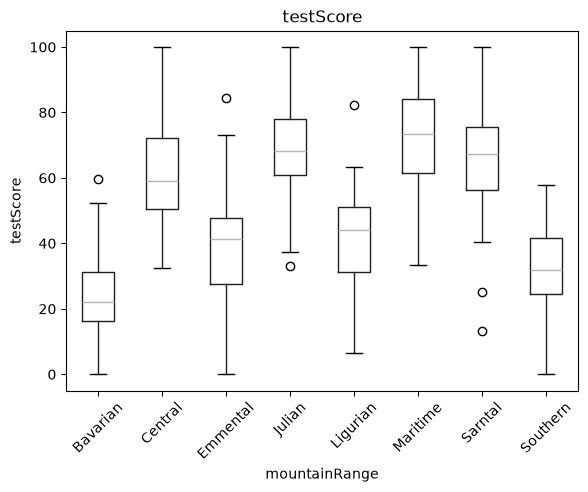

In [18]:
dragons.boxplot(column="testScore", by="mountainRange", rot=45, grid=False)
plt.suptitle(""); plt.ylabel("testScore"); plt.show()

**Tutorial R block 9**
```r
(colour_plot <- ggplot(dragons, aes(x = bodyLength, y = testScore, colour = mountainRange)) +
  geom_point(size = 2) + theme_classic() + theme(legend.position = "none"))
```
Python equivalent:

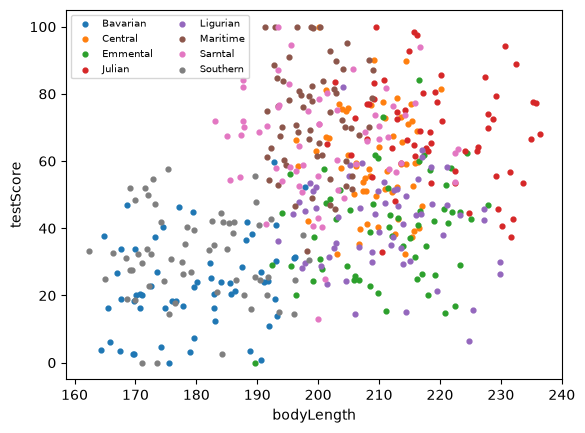

In [19]:
for name, g in dragons.groupby("mountainRange"):
    plt.scatter(g.bodyLength, g.testScore, s=12, label=name)
plt.xlabel("bodyLength"); plt.ylabel("testScore"); plt.legend(fontsize=7, ncol=2); plt.show()

## Run multiple analyses

**Tutorial R block 10**
```r
(split_plot <- ggplot(aes(bodyLength, testScore), data = dragons) +
  geom_point() + facet_wrap(~ mountainRange) + xlab("length") + ylab("test score"))
```
Python equivalent:

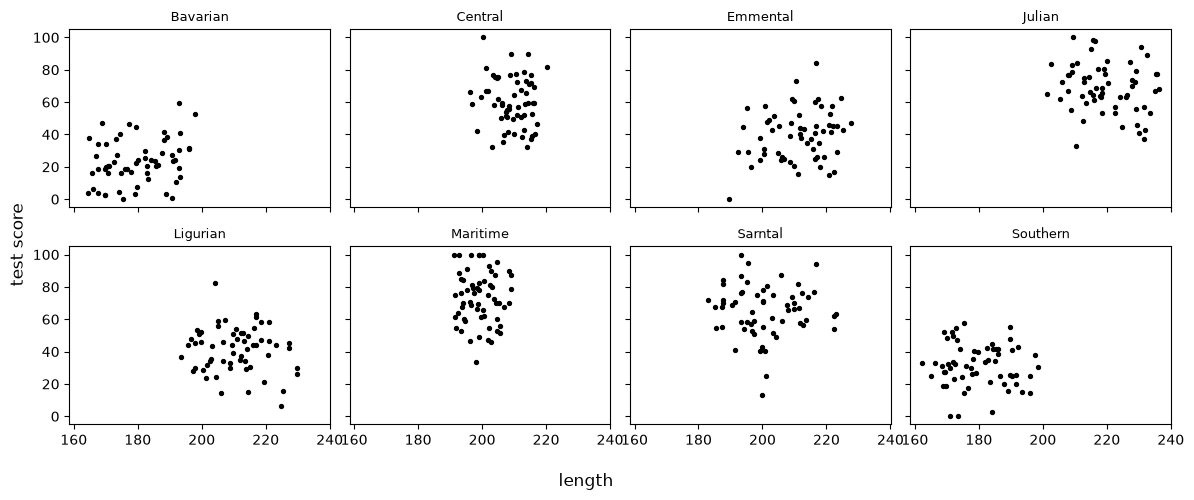

In [20]:
ranges = sorted(dragons.mountainRange.unique())
fig, axs = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, r in zip(axs.flat, ranges):
    g = dragons[dragons.mountainRange == r]
    ax.scatter(g.bodyLength, g.testScore, s=8, color="k"); ax.set_title(r, fontsize=9)
fig.supxlabel("length"); fig.supylabel("test score"); plt.tight_layout(); plt.show()

Fitting one model per range (or per site) means 8 or 24 small analyses with few dragons each, and more chance of false positives. The tutorial explains this.

## Modify the current model

**Tutorial R block 11**
```r
mountain.lm <- lm(testScore ~ bodyLength2 + mountainRange, data = dragons)
summary(mountain.lm)
```
Python equivalent:

In [21]:
mountain_lm = smf.ols("testScore ~ bodyLength2 + mountainRange", data=dragons).fit()
print(mountain_lm.summary())

                            OLS Regression Results                            
Dep. Variable:              testScore   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.577
Method:                 Least Squares   F-statistic:                     82.76
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           7.38e-85
Time:                        19:24:51   Log-Likelihood:                -1975.1
No. Observations:                 480   AIC:                             3968.
Df Residuals:                     471   BIC:                             4006.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

Body length is no longer significant once mountain range is in the model. But this spends 7 coefficients
estimating each range's difference from the reference, when the question isn't about ranges at all.
That's the motivation for mixed models in Part 2.